# Implicit Variational Inference with Adversarial Density-Ratio Estimation

**iCog Labs — Saturday AI training · walkthrough notebook**

This notebook walks through the ideas behind the code in `ivi/`. It runs one short training live,
then loads the cached results of the full experiments (`scripts/run_all.py`).

**The question.** Variational inference fits $q_\phi(z)\approx p(z\mid x)$ by minimising

$$\mathrm{KL}(q\,\|\,p(z\mid x)) \;=\; \mathbb{E}_q[\log q(z) - \log \tilde p(z)] + \log Z,
\qquad \tilde p(z)=p(z)\,p(x\mid z).$$

An *implicit* $q$ (a neural sampler $z=G_\phi(\varepsilon)$) can represent almost any shape, but
$\log q(z)$, needed for the first term, **cannot be evaluated**. Every method here is an answer to:
*what do we do about $\mathbb{E}_q[\log q(z)]$?*

In [1]:
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from ivi.targets import get_target, TARGETS
from ivi.plotting import setup_style, density_panel
from ivi.utils import method_config
from ivi.methods import build_method
from ivi.metrics import kl_knn
setup_style(); torch.set_num_threads(4)
FIG = ROOT / "figures"

## 1. Three hard 2D posteriors (with exact ground truth)

Each target is an unnormalised density. Because $z\in\mathbb{R}^2$ we can normalise it on a grid,
so we know $\log Z$ and can measure the **true** KL of any fitted $q$, which is rarely possible
in real problems.

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, name in zip(axes, TARGETS):
    t = get_target(name)
    density_panel(ax, t, contours=False, title=f"{t.title}   (log Z = {t.log_Z:.3f})")
plt.show()

## 2. The explicit baseline and why it fails

Full-covariance Gaussian VI has a closed-form $\log q$, so the objective is exact and cheap.
But an ellipse cannot bend (banana), cross (X) or split (mixture), and reverse KL makes it
*mode-seeking*: it shrinks into one region rather than cover low-density gaps.

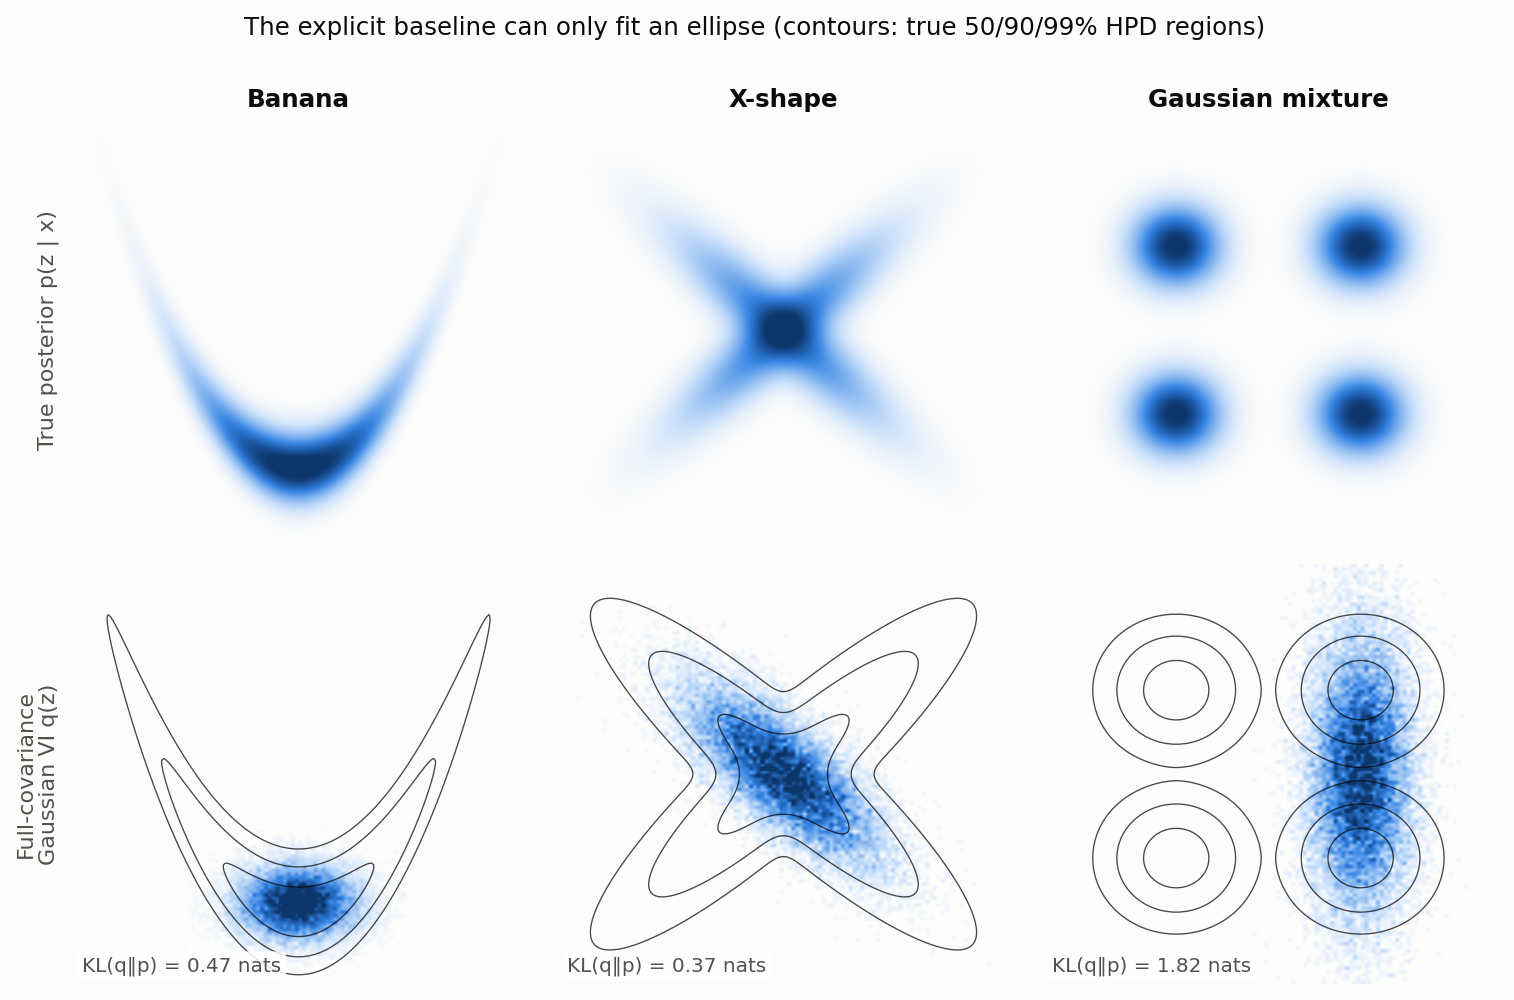

In [3]:
display(Image(FIG / "01_targets_and_gaussian_vi.png", width=850))

## 3. Adversarial density-ratio estimation (main method)

Add and subtract the log density of any tractable reference $r(z)$ that covers $q$:

$$\mathbb{E}_q[\log q-\log\tilde p] \;=\; \underbrace{\mathbb{E}_q\!\left[\log\tfrac{q(z)}{r(z)}\right]}_{\text{intractable ratio}} \;+\; \underbrace{\mathbb{E}_q[\log r(z)-\log\tilde p(z)]}_{\text{exact given samples}}.$$

A classifier $T_\psi$ trained with the logistic loss to separate $q$-samples (label 1) from
$r$-samples (label 0) has optimum $\sigma(T^*)=\frac{q}{q+r}$, i.e.
$$T^*(z)=\log q(z)-\log r(z).$$
So the generator minimises $\mathbb{E}_\varepsilon[T(G(\varepsilon))+\log r(G(\varepsilon))-\log\tilde p(G(\varepsilon))]$.

**Why $T$ can be held fixed in the generator step.** $T^*$ depends on $\phi$, but
$\nabla_\phi\mathbb{E}_q[T^*] = \mathbb{E}_\varepsilon[\nabla_z T^*\cdot\partial_\phi G] + \mathbb{E}_q[\nabla_\phi\log q_\phi(z)]$
and the last term is $0$ (score-function identity). So at the optimal classifier the pathwise
gradient is the full gradient. Hence the **alternating loop**: re-fit $T$ for $k$ steps, then
one generator step with $T$ frozen.

The core of the update (from `ivi/methods/adversarial.py`):

In [4]:
import inspect
from ivi.methods.adversarial import AdversarialVI
print(inspect.getsource(AdversarialVI.discriminator_step))
print(inspect.getsource(AdversarialVI.generator_step))

    def discriminator_step(self, ref) -> tuple[float, float]:
        """One logistic-regression step: q-samples labelled 1, r-samples 0."""
        with torch.no_grad():
            zq = self.generate(self.batch_size)
            zr = ref.sample((self.batch_size,))
        logit_q = self.discriminator(zq).squeeze(-1)
        logit_r = self.discriminator(zr).squeeze(-1)
        # -log sigmoid(t) = softplus(-t);  -log(1 - sigmoid(t)) = softplus(t)
        loss = F.softplus(-logit_q).mean() + F.softplus(logit_r).mean()
        self.opt_d.zero_grad()
        loss.backward()
        self.opt_d.step()
        acc = 0.5 * ((logit_q > 0).float().mean() + (logit_r < 0).float().mean())
        return loss.item(), acc.item()

    def generator_step(self, ref) -> tuple[float, torch.Tensor]:
        """One step on the estimated KL with the ratio estimator T held fixed."""
        z = self.generate(self.batch_size)
        with frozen(self.discriminator):
            log_ratio = self.discriminator(

### Live: a short adversarial run on the banana (about 30 s on a laptop CPU)

In [5]:
torch.manual_seed(0)
t = get_target("banana")
m = build_method("adversarial", t, method_config("adversarial", target="banana"))
snaps, t0 = {}, time.time()
for it in range(1, 1501):
    logs = m.step()
    if it in (1, 100, 300, 1500):
        snaps[it] = m.sample(5000).numpy()
print(f"{time.time()-t0:.1f}s   classifier acc {logs['disc_acc']:.3f}   own KL estimate {logs['kl_est']:.3f}")
print("true KL(q||p) =", round(kl_knn(m.sample(20000).numpy(), t)["kl_knn"], 4))
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (it, s) in zip(axes, snaps.items()):
    density_panel(ax, t, s, title=f"iteration {it}")
plt.show()

25.2s   classifier acc 0.907   own KL estimate -0.005
true KL(q||p) = 0.0121


## 4. Does the classifier really learn $\log q - \log r$?

We compare the learned logit with an *independent* estimate (KDE of $q$ minus the exact $\log r$),
using the fully trained models. This agreement is what justifies the whole method.

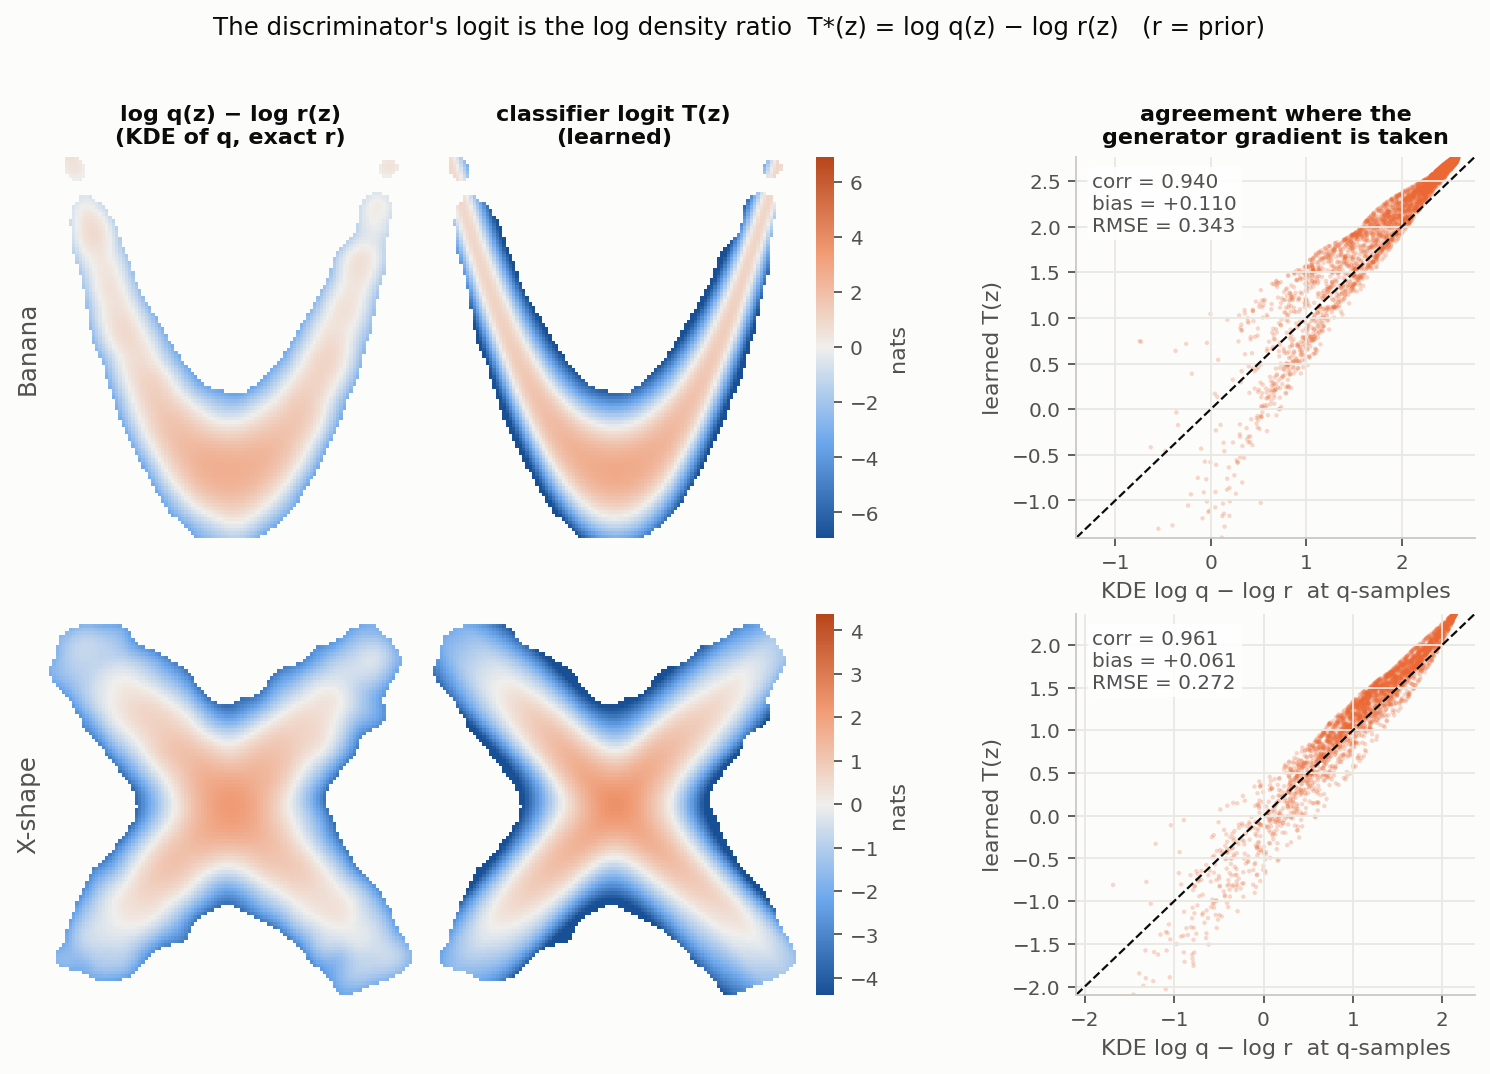

In [6]:
display(Image(FIG / "03_density_ratio_check.png", width=900))

## 5. Why the optimisation behaves the way it does

* **Classifier accuracy does not go to 50 %.** With a fixed prior reference, the best possible
  accuracy when $q=p$ is $\tfrac12(1+\mathrm{TV}(p,r))$, and that is where it settles (dashed line).
* **The method's own KL estimate is biased**: noisy, and it can dip below zero (impossible for a
  true KL). It is only as good as the classifier.
* **Separated modes are found one split at a time**: the KL falls in steps ($\log 4\to\log 2\to 0$).

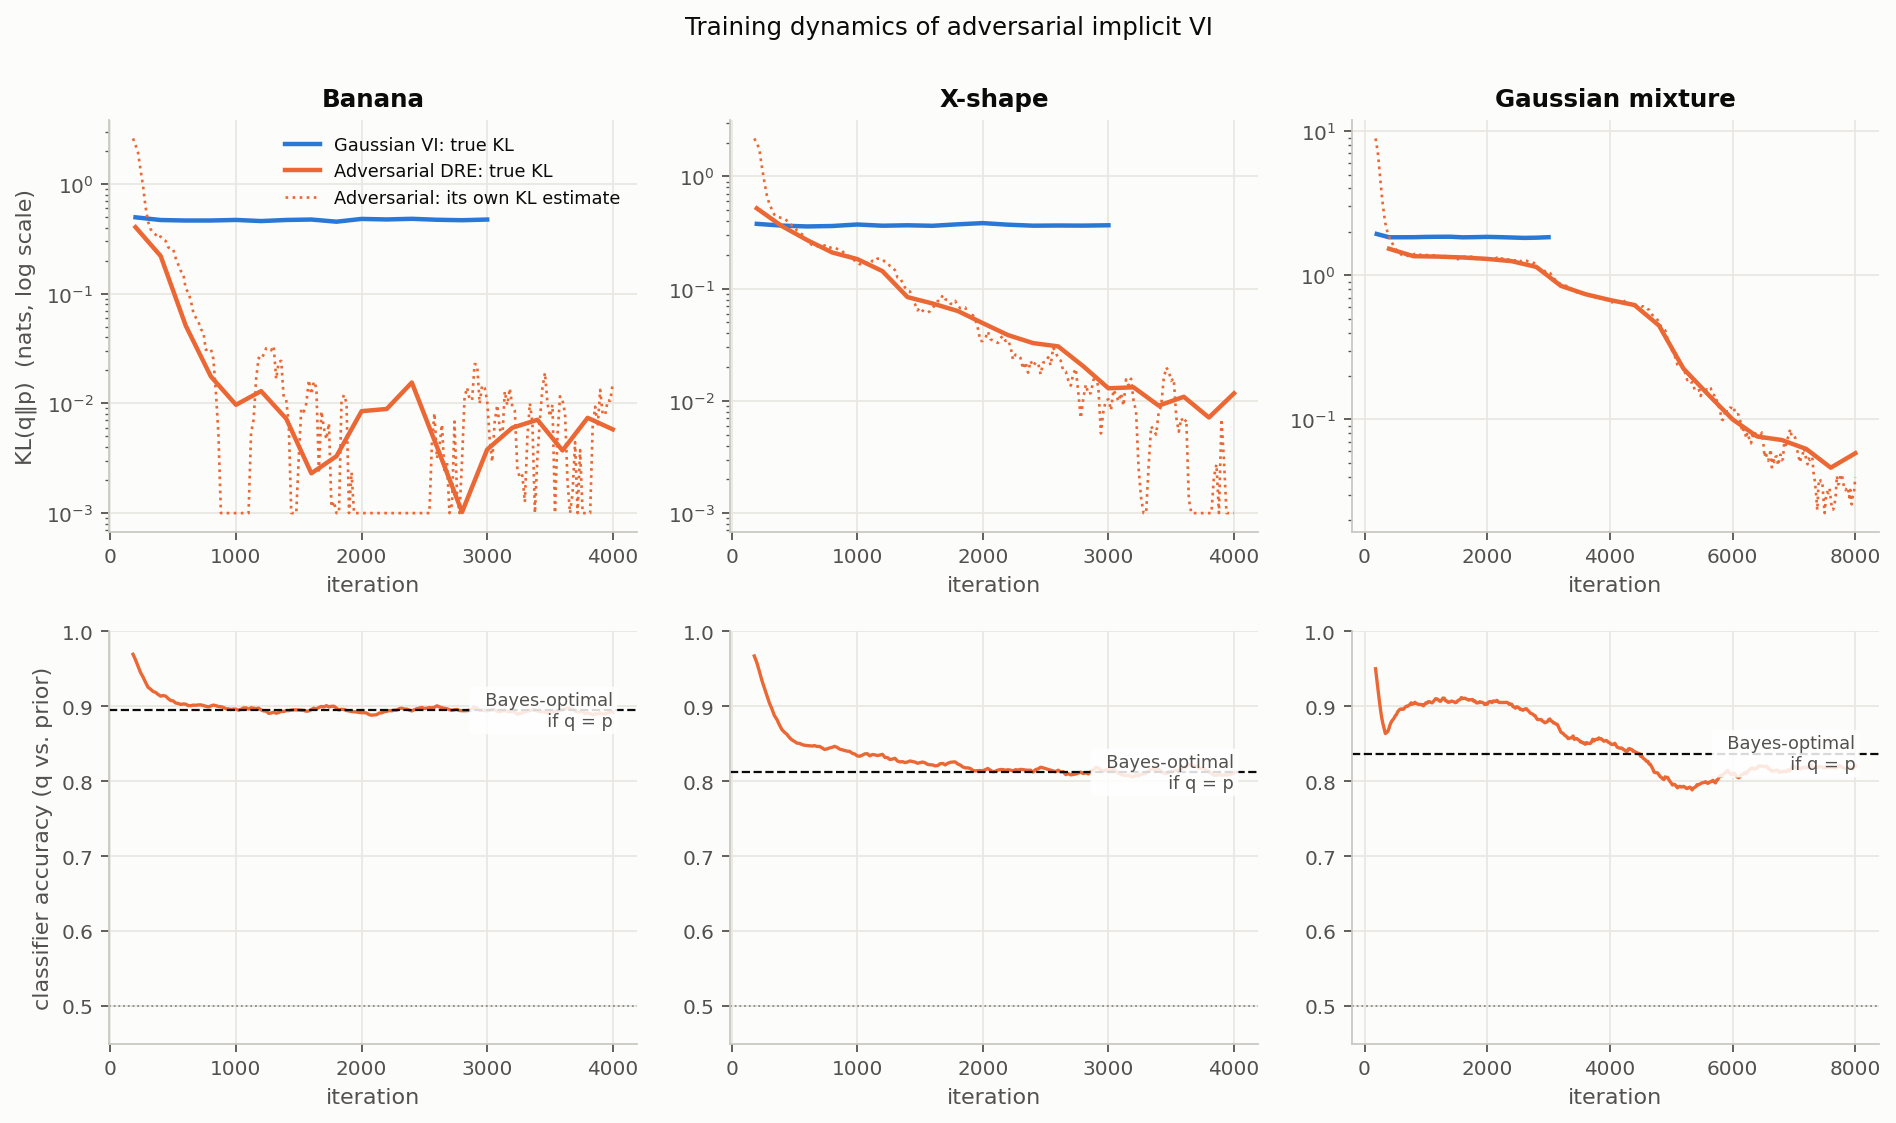

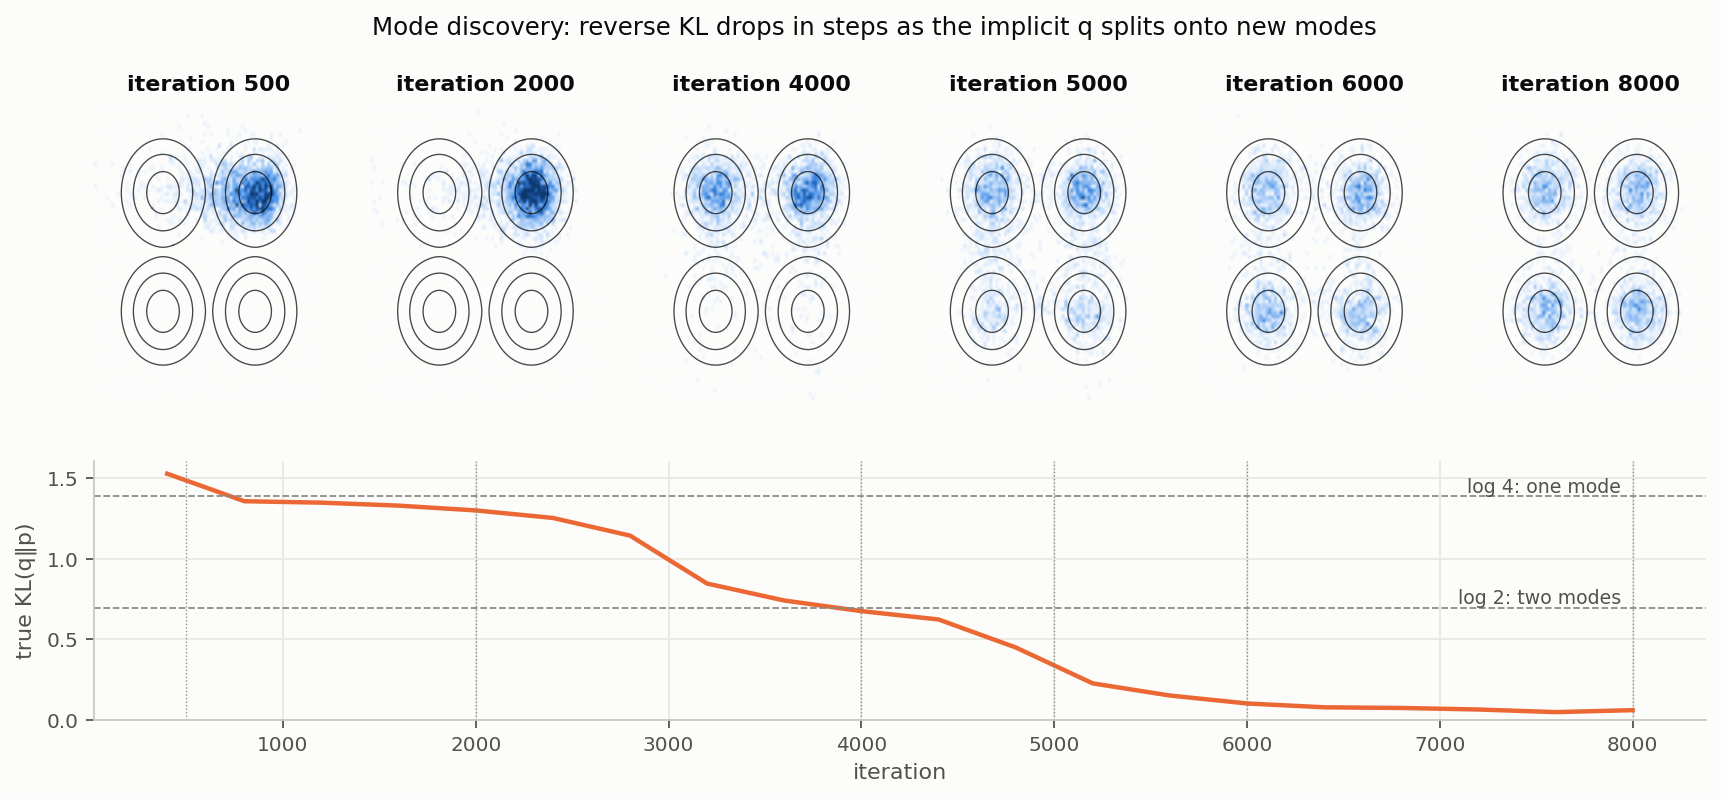

In [7]:
display(Image(FIG / "04_training_dynamics.png", width=900))
display(Image(FIG / "05_mode_discovery.png", width=900))

### Ablations: inner-loop length and the choice of $r$

* More classifier steps per generator step mean a less biased gradient (diminishing returns, higher cost).
* **The tails of $r$ matter.** The "tractable" term $\mathbb{E}_q[\log r-\log\tilde p]$ is unbounded
  below wherever $r$ has lighter tails than the posterior (along the banana's arms). There only the
  ratio estimate stops $q$ from escaping, and estimators are least accurate exactly where $q$ has
  few samples. A moving, moment-matched $r$ made this worse in 2D (3 % of samples leaked).

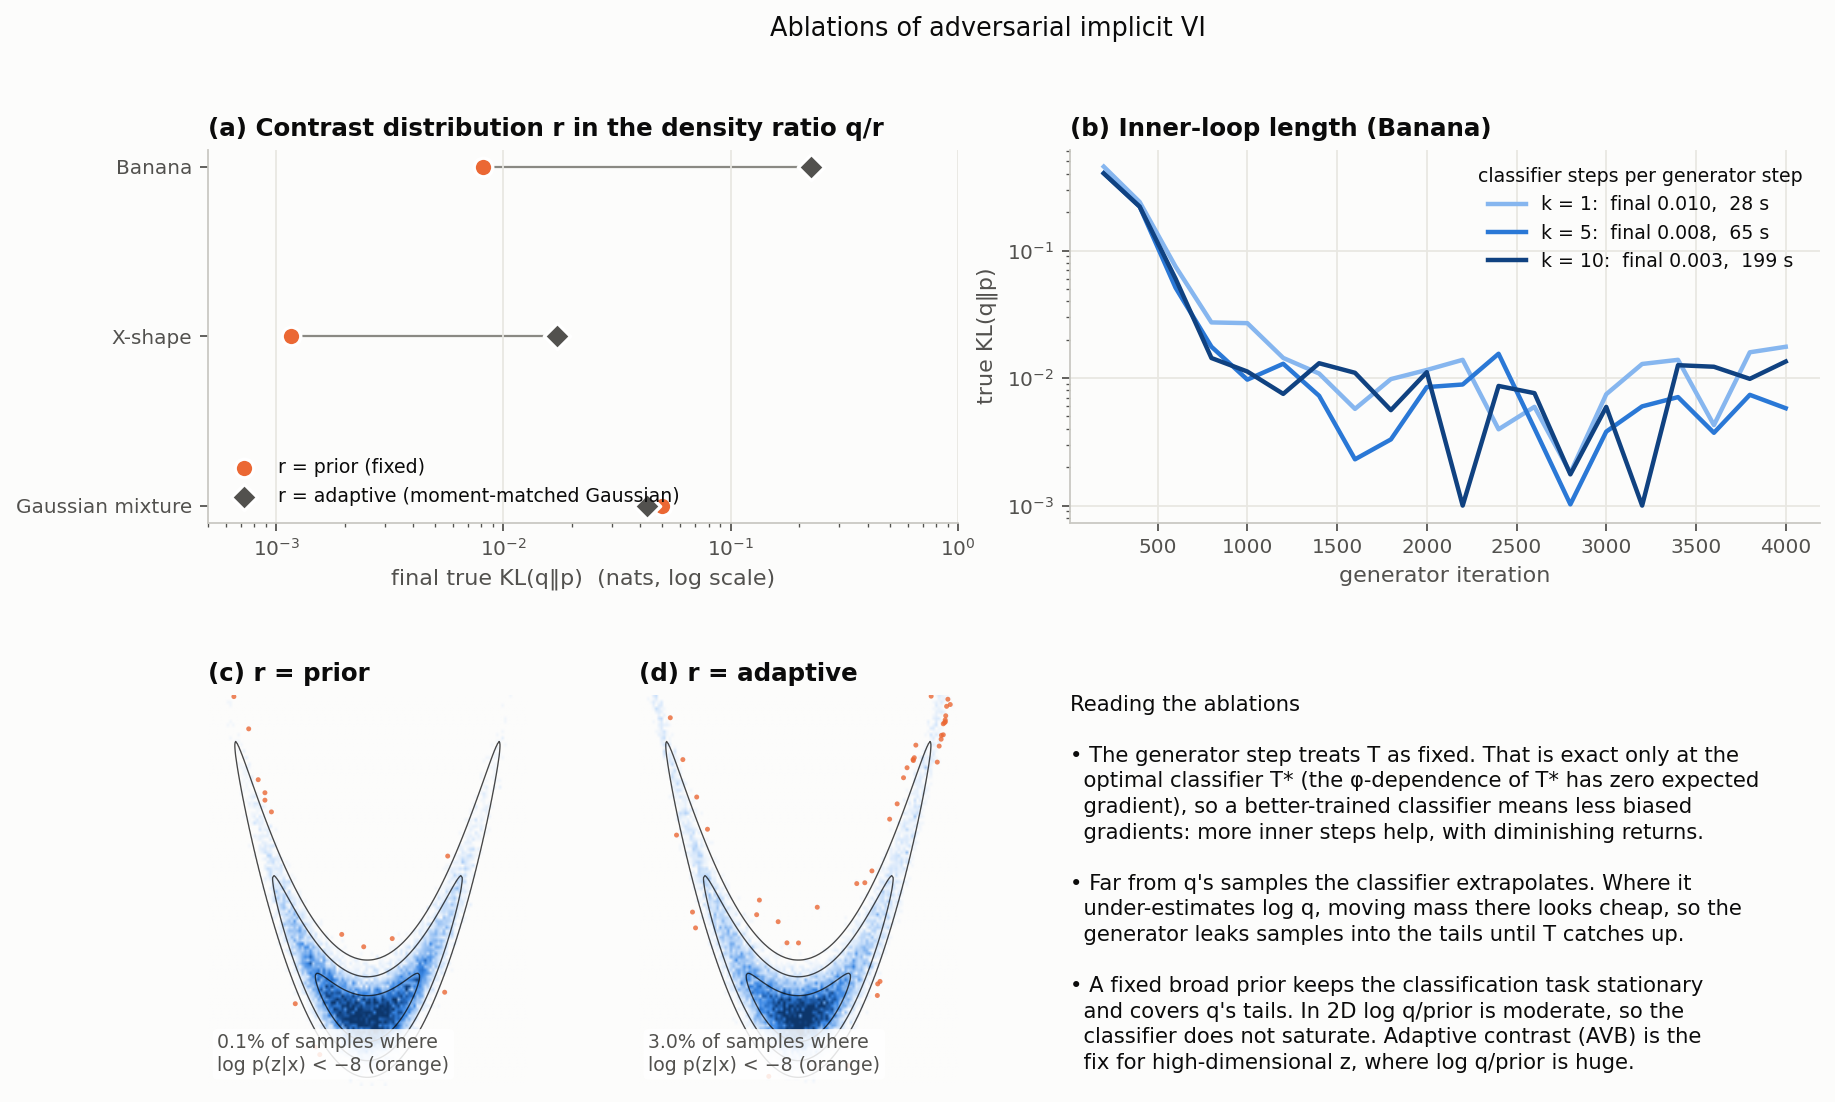

In [8]:
display(Image(FIG / "06_ablations.png", width=900))

## 6. Bonus: two other answers to the same question

**KIVI** keeps the ratio decomposition but estimates $q/r$ by closed-form kernel least squares:
$\hat\rho(z)=\sum_j\alpha_j k(z,c_j)$ with $\alpha=(H+\lambda I)^{-1}g$. There is no inner
optimisation and no adversarial game, but the difficulty moves into the bandwidth, the ridge
and the tails of $r$.

**SIVI** avoids ratios entirely. With $q(z)=\mathbb{E}_{\psi}[q(z\mid\psi)]$ and an explicit
Gaussian conditional, it maximises
$$\mathcal{L}_K=\mathbb{E}\Big[\log\tilde p(z)-\log\tfrac{1}{K+1}\textstyle\sum_{k=0}^{K}q(z\mid\psi^{(k)})\Big]\;\le\;\text{ELBO},$$
which increases monotonically in $K$. $K=0$ reduces to Gaussian VI.

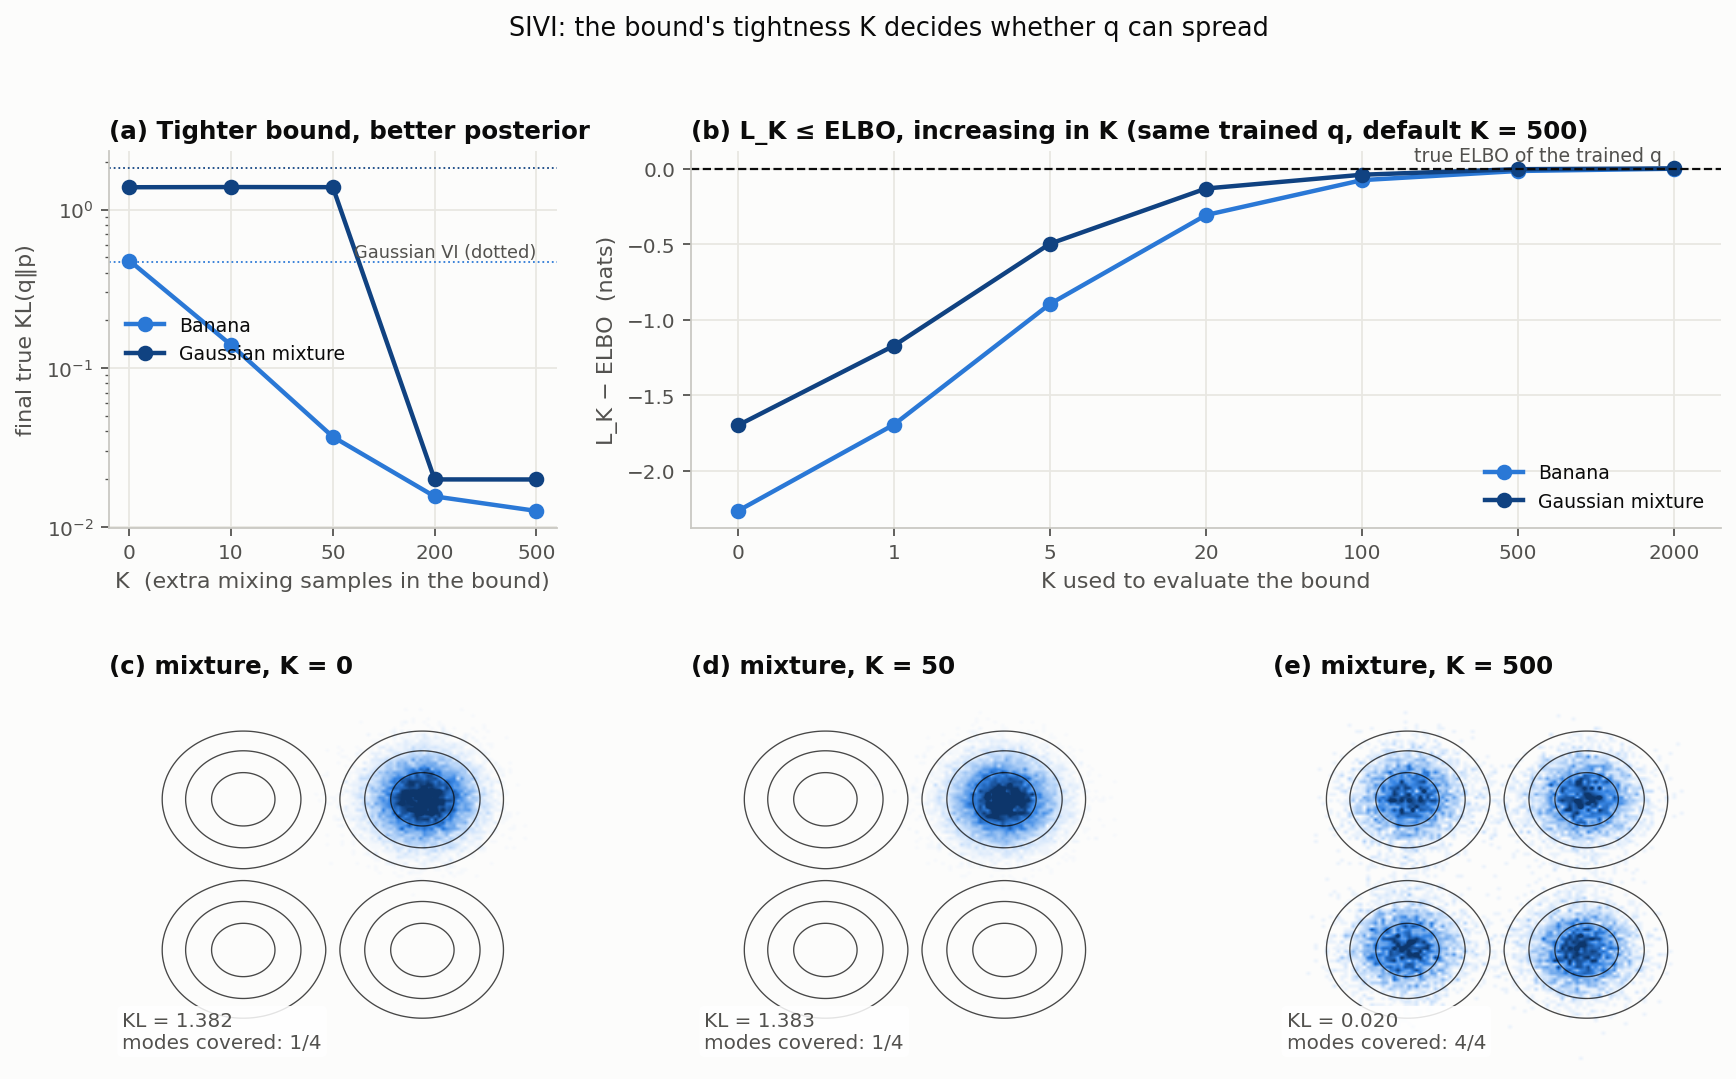

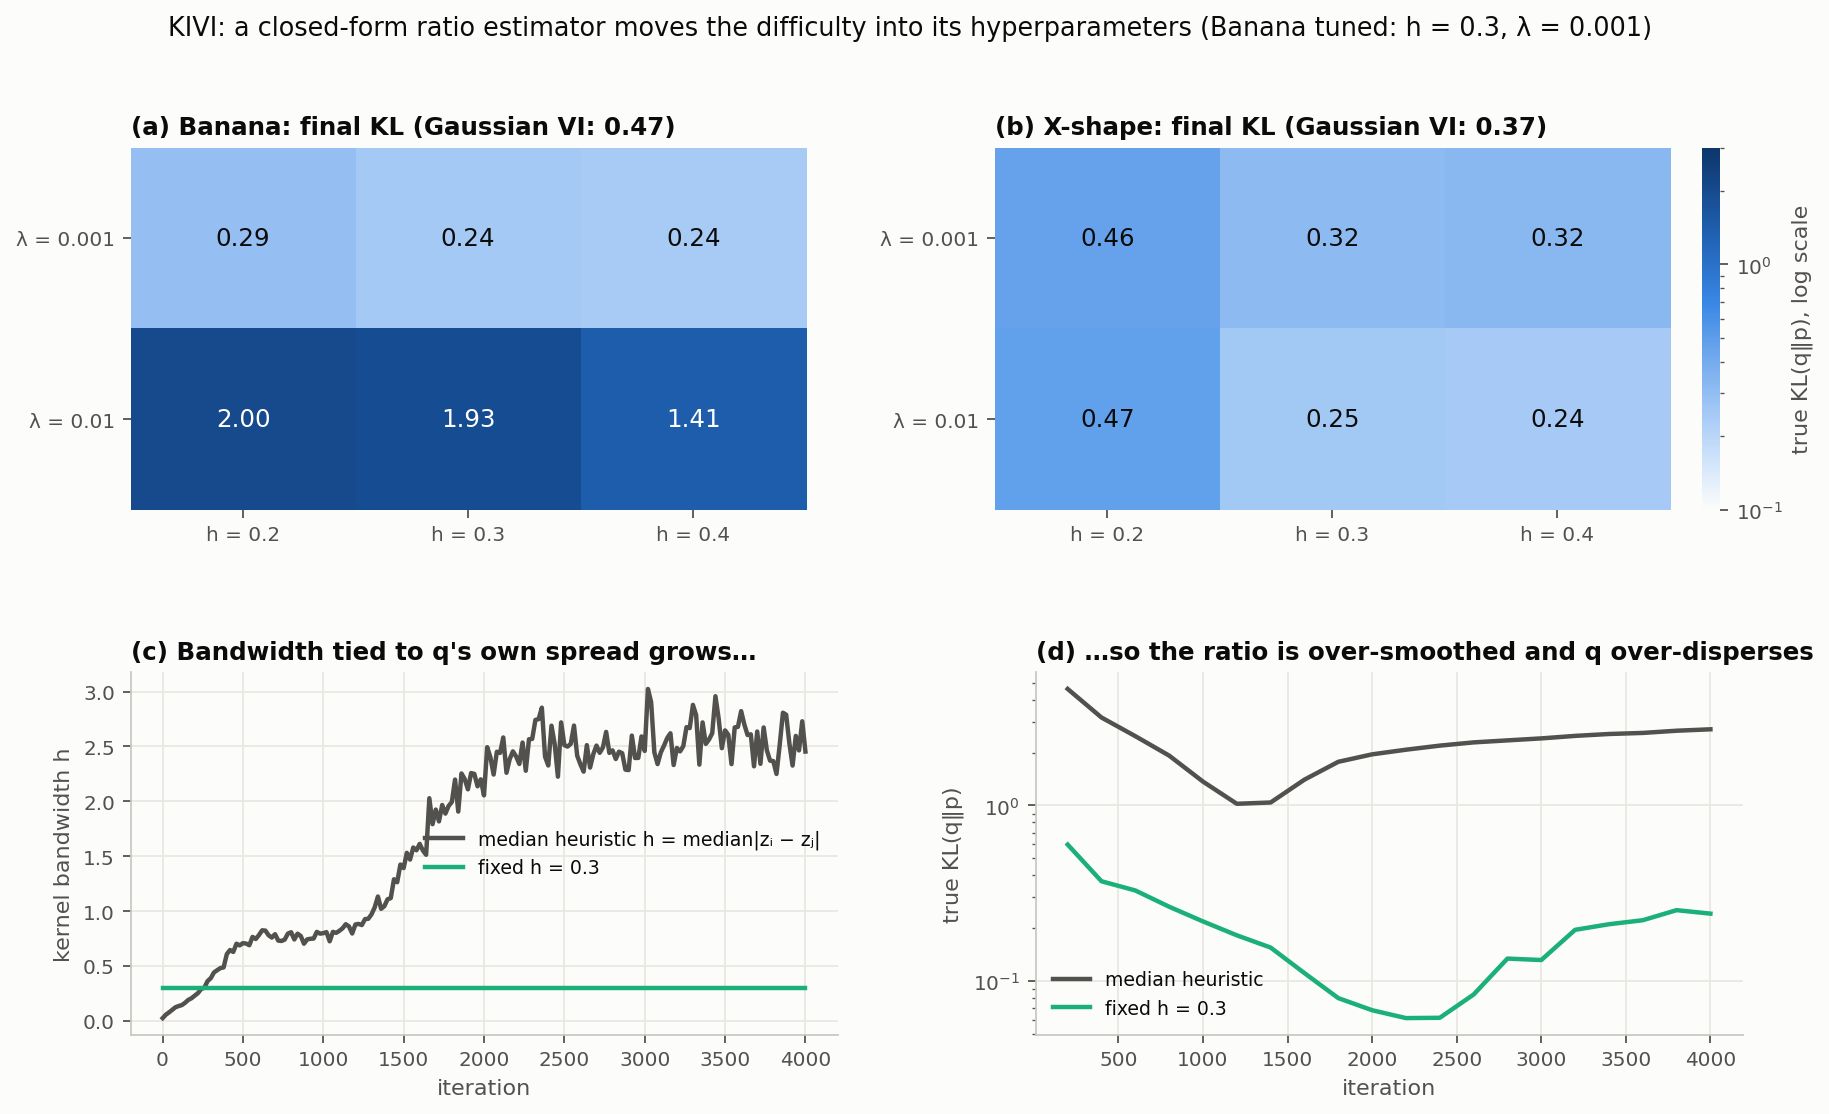

In [9]:
display(Image(FIG / "07_sivi_bound.png", width=900))
display(Image(FIG / "08_kivi_sensitivity.png", width=900))

## 7. Head-to-head over 3 seeds

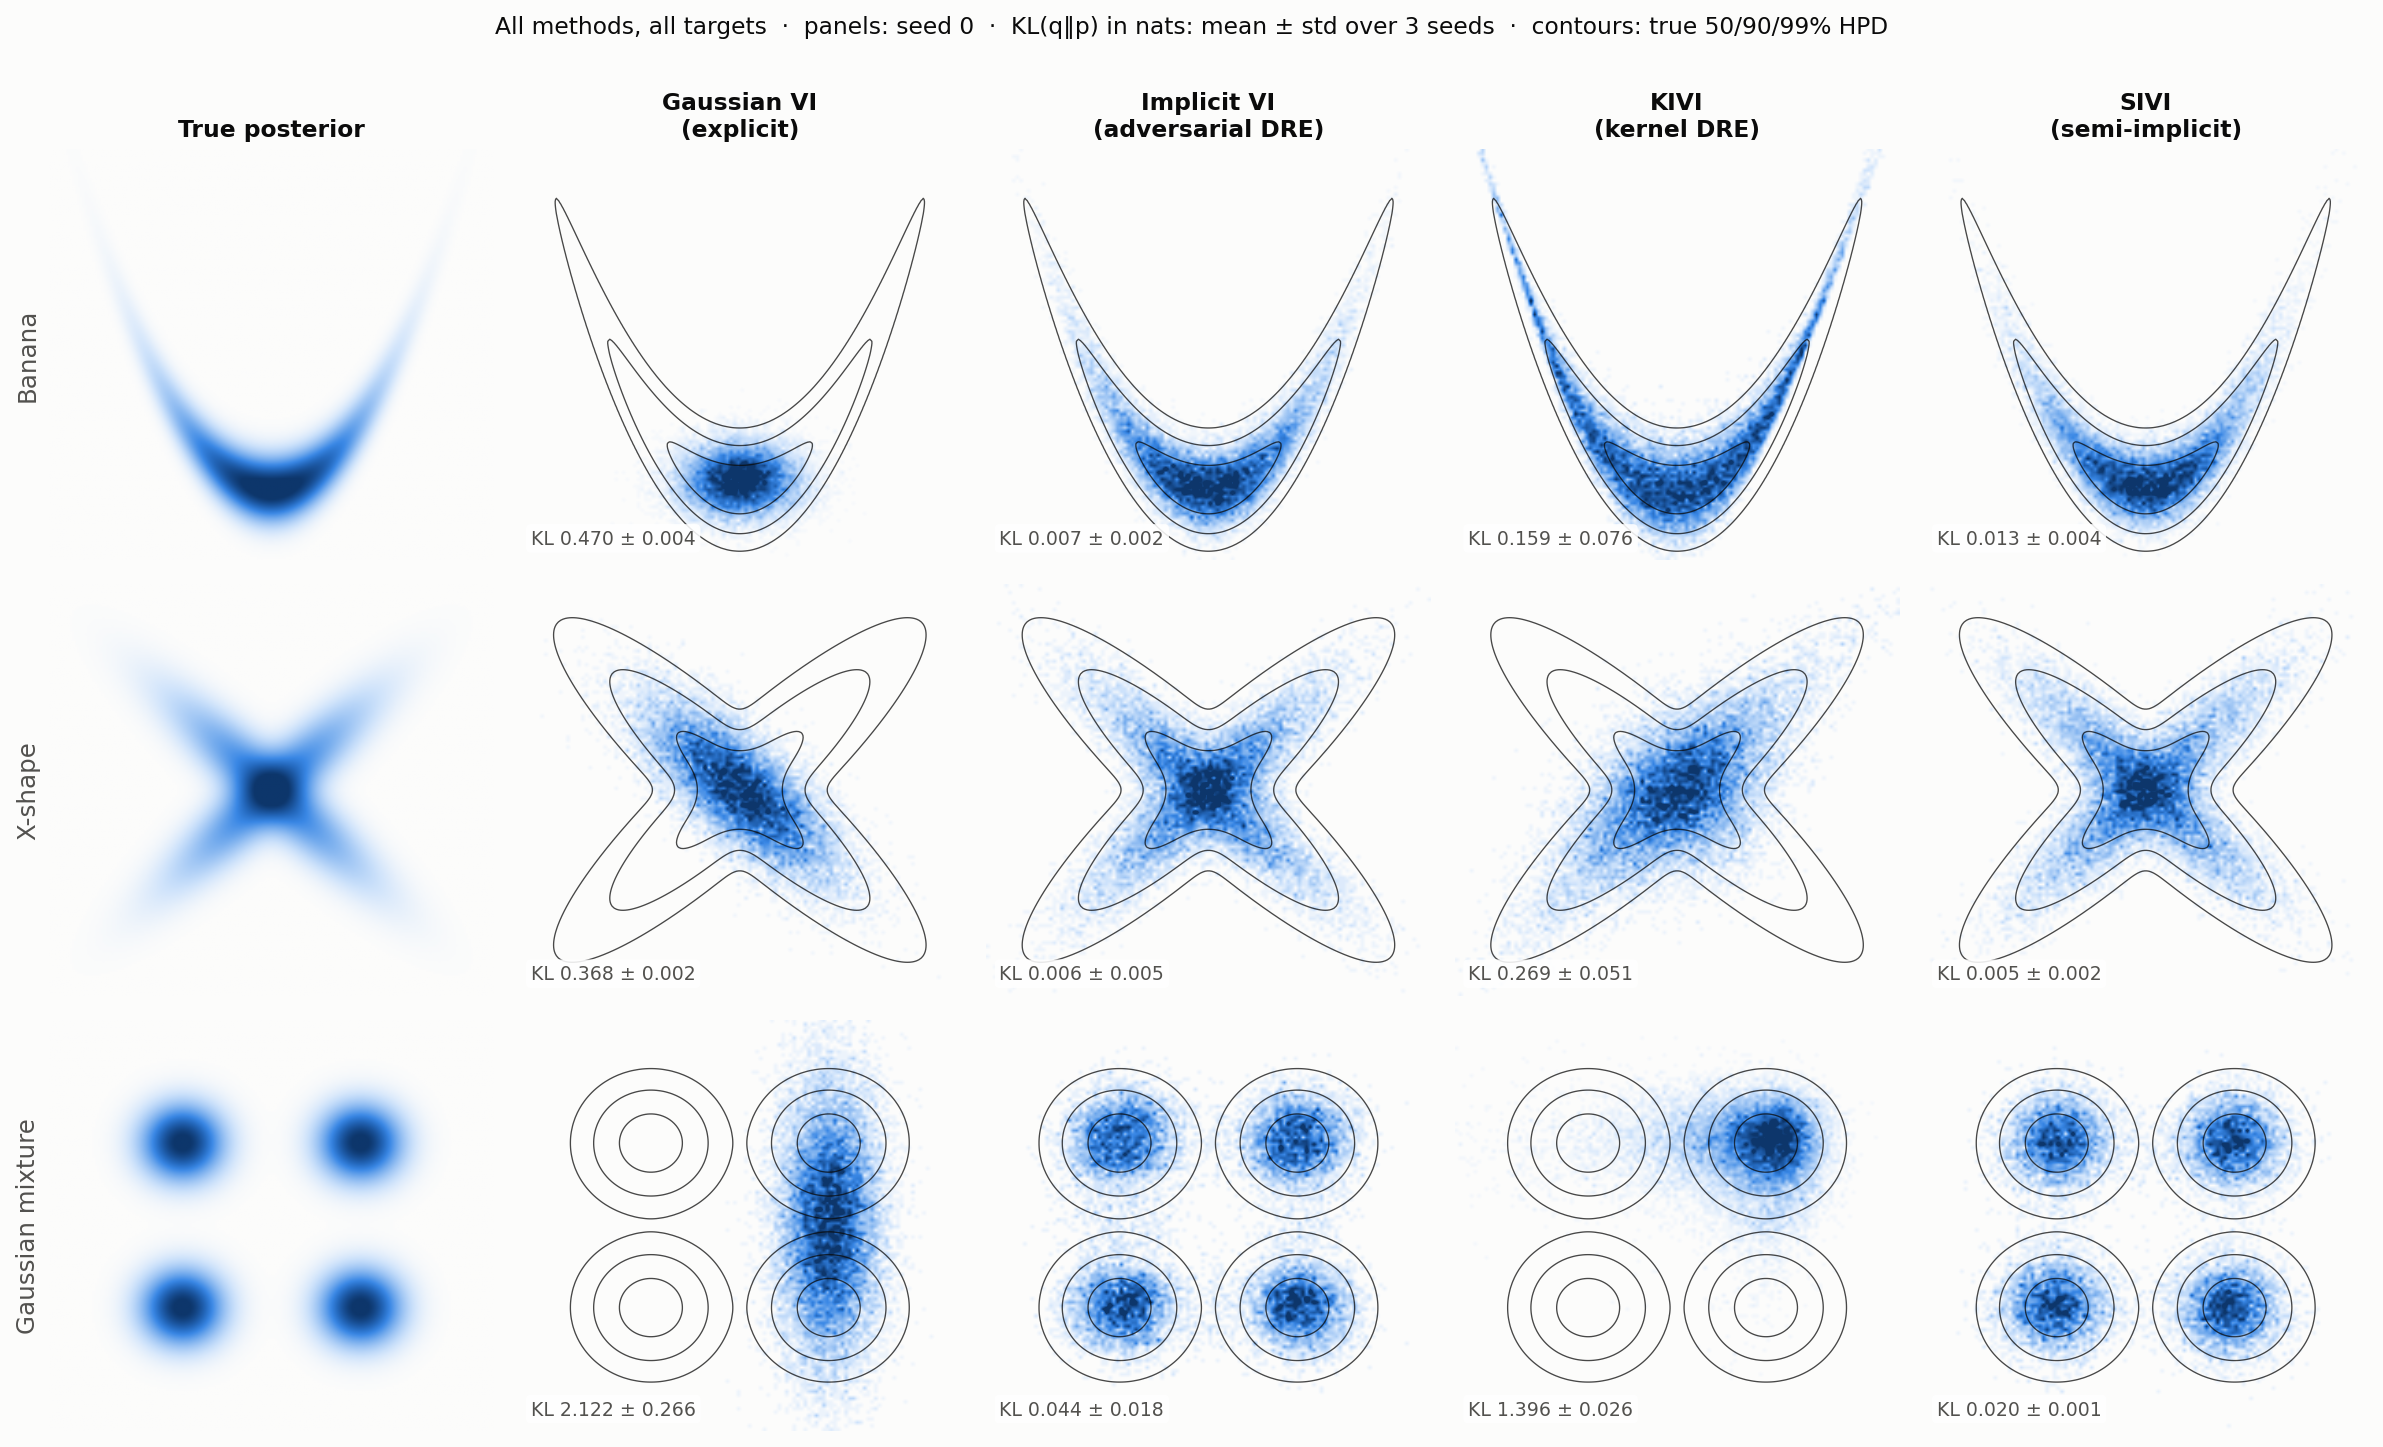

# Comparison over 3 seeds (mean ± std)

KL(q‖p): binning-free kNN estimate of the reverse KL (the VI objective). KL(p‖q): forward KL on a 50×50 grid (punishes missing mass). TV: total variation on the same grid. Time: optimisation wall-clock on a 4-core CPU VM. Mixture: a mode counts if q puts ≥5% of its mass within 3 sd of it; 'mass between modes' exposes broad blobs that touch every mode without fitting any.

## Banana

| Method | KL(q‖p) | KL(p‖q) | TV | Time (s) |
|---|---|---|---|---|
| Gaussian VI | 0.470 ± 0.004 | 1.345 ± 0.013 | 0.351 ± 0.002 | 2 |
| Adversarial DRE | 0.007 ± 0.002 | 0.009 ± 0.002 | 0.033 ± 0.003 | 73 |
| KIVI | 0.159 ± 0.076 | 0.132 ± 0.071 | 0.162 ± 0.042 | 26 |
| SIVI | 0.013 ± 0.004 | 0.019 ± 0.004 | 0.046 ± 0.006 | 33 |

## X-shape

| Method | KL(q‖p) | KL(p‖q) | TV | Time (s) |
|---|---|---|---|---|
| Gaussian VI | 0.368 ± 0.002 | 1.069 ± 0.018 | 0.305 ± 0.001 | 2 |
| Adversarial DRE | 0.006 ± 0.005 | 0.015 ± 0.002 | 0.052 ± 0.007 | 74 |
| KIVI | 0.269 ± 0.051 | 0.468 ± 0.038 | 0.215 ± 0.025 | 28 |
| SIVI | 0.005 ± 0.002 | 0.014 ± 0.001 | 0.043 ± 0.001 | 32 |

## Gaussian mixture

| Method | KL(q‖p) | KL(p‖q) | TV | Time (s) | Modes with ≥5% mass | Mass between modes |
|---|---|---|---|---|---|---|
| Gaussian VI | 2.122 ± 0.266 | 1.986 ± 1.430 | 0.612 ± 0.034 | 2 | 2/4, 4/4, 4/4 | 18%, 40%, 40% |
| Adversarial DRE | 0.044 ± 0.018 | 0.035 ± 0.011 | 0.075 ± 0.018 | 180 | 4/4, 4/4, 4/4 | 3%, 3%, 3% |
| KIVI | 1.396 ± 0.026 | 3.768 ± 1.196 | 0.707 ± 0.034 | 65 | 2/4, 2/4, 1/4 | 9%, 9%, 3% |
| SIVI | 0.020 ± 0.001 | 0.023 ± 0.002 | 0.067 ± 0.005 | 72 | 4/4, 4/4, 4/4 | 2%, 2%, 2% |


In [10]:
display(Image(FIG / "09_comparison_grid.png", width=950))
display(Markdown((ROOT / "results" / "comparison_table.md").read_text()))

## 8. The trade-offs in one table

| | How $\mathbb{E}_q[\log q]$ is handled | Gradient | Main failure mode | Cost per step |
|---|---|---|---|---|
| **Gaussian VI** | exact (closed form) | unbiased, low variance | family too simple: ellipse, mode-seeking | tiny |
| **Adversarial DRE** | learned classifier logit $T\approx\log q/r$ | biased unless $T=T^*$; needs inner loop | classifier lag gives tail leakage and noisy, biased KL estimates | $k$ classifier steps + 1 |
| **KIVI** | closed-form kernel least squares for $q/r$ | biased (ridge shrinkage, smoothing); refit from scratch each step | bandwidth and ridge sensitivity; cannot extrapolate; poor in high dimension | $O(b^3)$ solve |
| **SIVI** | lower bound $\mathcal{L}_K$ with a $K$-sample mixture | exact gradient of a bound | small $K$ gives under-dispersion and mode collapse | $O(BK)$ density evaluations |